In [2]:
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

I0000 00:00:1794963756.710479    5722 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794963756.833464    5722 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794963772.044466    5722 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794963785.773242    5722 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [3]:
keras.utils.set_random_seed(42)

In [4]:
df = pd.read_csv("heart.csv")

In [5]:
df.shape

(303, 14)

In [6]:
df.head(7)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,reversible,0
3,37,1,3,130,250,0,0,187,0,3.5,3,0,normal,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,normal,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0,normal,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2,normal,1


In [7]:
df.target.value_counts(normalize=True, dropna=False)

target
0    0.726073
1    0.273927
Name: proportion, dtype: float64

In [8]:
df.target.value_counts(normalize=True).max()


np.float64(0.7260726072607261)

In [9]:
categorical_variables = ['sex', 'cp', 'fbs', 'restecg','exang', 'ca', 'thal']
numerics = ['age', 'trestbps','chol', 'thalach', 'oldpeak', 'slope']

In [10]:
df1 = pd.get_dummies(df, columns = categorical_variables, dtype=int)

In [11]:
df1.head(7)

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,exang_1,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible
0,63,145,233,150,2.3,3,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
1,67,160,286,108,1.5,2,1,0,1,0,...,1,0,0,0,1,0,0,0,1,0
2,67,120,229,129,2.6,2,0,0,1,0,...,1,0,0,1,0,0,0,0,0,1
3,37,130,250,187,3.5,3,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0
4,41,130,204,172,1.4,1,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0
5,56,120,236,178,0.8,1,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0
6,62,140,268,160,3.6,3,1,1,0,0,...,0,0,0,1,0,0,0,0,1,0


In [12]:
test_df = df1.sample(frac=0.2, random_state=42)
train_df = df1.drop(test_df.index)

In [13]:
train_df.shape

(242, 30)

In [14]:
test_df.shape

(61, 30)

In [15]:
means = train_df[numerics].mean()
sd = train_df[numerics].std()

In [16]:
train_df.head()

,age,trestbps,chol,thalach,oldpeak,slope,target,sex_0,sex_1,cp_0,...,exang_1,ca_0,ca_1,ca_2,ca_3,thal_1,thal_2,thal_fixed,thal_normal,thal_reversible
0,63,145,233,150,2.3,3,0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
1,67,160,286,108,1.5,2,1,0,1,0,...,1,0,0,0,1,0,0,0,1,0
2,67,120,229,129,2.6,2,0,0,1,0,...,1,0,0,1,0,0,0,0,0,1
3,37,130,250,187,3.5,3,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0
4,41,130,204,172,1.4,1,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0


In [17]:
train = train_df.to_numpy()
test = test_df.to_numpy()

In [18]:
train_X = np.delete(train, 6, axis=1)
test_X = np.delete(test, 6, axis=1)

In [19]:
train_X.shape, test_X.shape

((242, 29), (61, 29))

In [20]:
train_y = train[:, 6]
test_y = test[:, 6]

In [21]:
train_y.shape, test_y.shape

((242,), (61,))

## Создание модели

In [32]:
num_columns = train_X.shape[1]

# define the input layer
input = keras.Input(shape=(num_columns,))

# feed the input vector to the hidden layer
# optional: you can give names to each layer to help
# keep track. This doesn't affect the training etc.

h = keras.layers.Dense(16, activation="relu", name="spryatanniy")(input)

# feed the output of the hidden layer to the output layer
output = keras.layers.Dense(1, activation="sigmoid", name="vivedenniy")(h)

# tell Keras that this (input,output) pair is your model
model = keras.Model(input, output, name="Nyahahahaha")

In [33]:
model.summary()

Model: "Nyahahahaha"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 29)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spryatanniy (Dense)             │ (None, 16)             │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vivedenniy (Dense)              │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 497 (1.94 KB)

 Trainable params: 497 (1.94 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
17-(38+11)*0.5+3000

2992.5

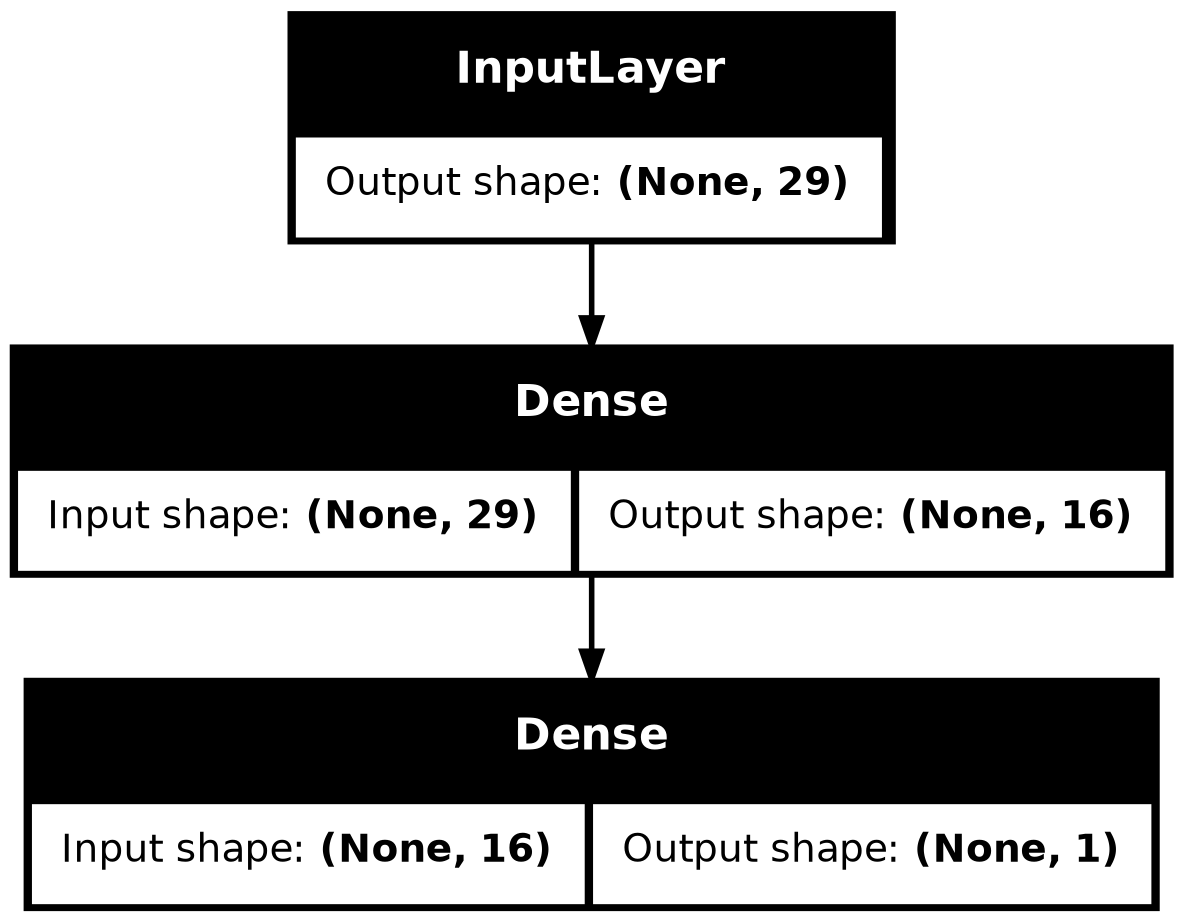

In [35]:
keras.utils.plot_model(model, show_shapes=True)

In [36]:
model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

In [38]:
history = model.fit(train_X,              # массив со входными столбцами признаков X
                    train_y,              # массив с выходным (целевым) столбцом y.
                    epochs=100,           # количество эпох (полных проходов по данным) для обучения.
                    batch_size=32,        # количество примеров (то есть точек данных) в одном пакете (батче).
                    verbose=1,            # уровень подробности вывода информации во время обучения (1 означает показывать прогресс-бар).
                    validation_split=0.2) # • использовать 20% данных для валидации (проверки качества модели на каждом шаге).

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8756 - loss: 0.2974 - val_accuracy: 0.8163 - val_loss: 0.4544
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8756 - loss: 0.2971 - val_accuracy: 0.8163 - val_loss: 0.4541
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8756 - loss: 0.2968 - val_accuracy: 0.8163 - val_loss: 0.4541
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8756 - loss: 0.2965 - val_accuracy: 0.8163 - val_loss: 0.4538
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8756 - loss: 0.2962 - val_accuracy: 0.8163 - val_loss: 0.4539
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8756 - loss: 0.2959 - val_accuracy: 0.8163 - val_loss: 0.4536
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8756 - loss: 0.2956 - val_accuracy: 0.8163 - val_loss: 0.4536
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8756 - loss: 0.2953 - val_accuracy: 0.8163 - val_loss: 0.453

In [39]:
history_dict = history.history
history_dict.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

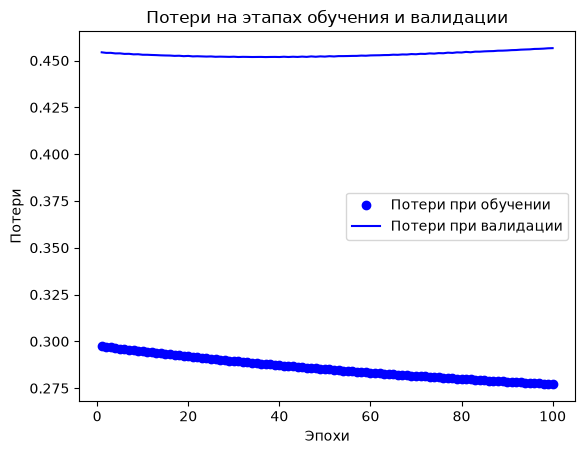

In [42]:
loss_values = history_dict["loss"]
val_loss_values = history_dict["val_loss"]
epochs = range(1, len(loss_values) + 1)
plt.plot(epochs, loss_values, "bo", label="Потери при обучении")
plt.plot(epochs, val_loss_values, "b", label="Потери при валидации")
plt.title("Потери на этапах обучения и валидации")
plt.xlabel("Эпохи")
plt.ylabel("Потери")
plt.legend()
plt.show()

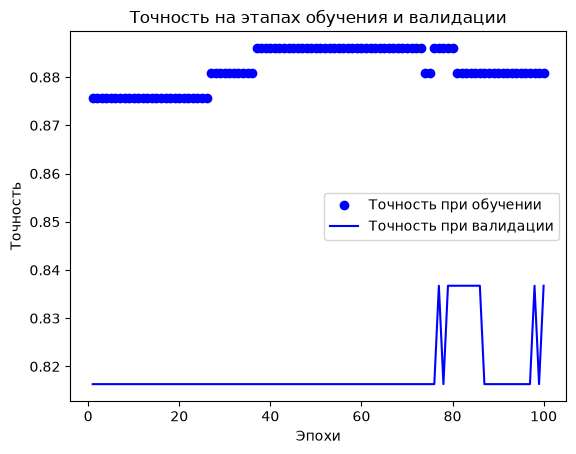

In [43]:
plt.clf()
acc = history_dict["accuracy"]
val_acc = history_dict["val_accuracy"]
plt.plot(epochs, acc, "bo", label="Точность при обучении")
plt.plot(epochs, val_acc, "b", label="Точность при валидации")
plt.title("Точность на этапах обучения и валидации")
plt.xlabel("Эпохи")
plt.ylabel("Точность")
plt.legend()
plt.show()

In [44]:
model.evaluate(test_X, test_y)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8197 - loss: 0.3463


[0.34631574153900146, 0.8196721076965332]